In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
POLLUTANT = "pm10"
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
TEST_FRACTION = 0.2

In [3]:
PROCESSED_DIR = Path("../data/processed")
FEATURES_FILE = PROCESSED_DIR / f"features_{POLLUTANT}.parquet"

In [4]:
df = pd.read_parquet(FEATURES_FILE)
df["date"] = pd.to_datetime(df["date"])

In [5]:
lag_cols = [f"{POLLUTANT}_lag_{d}" for d in LAGGED_DAYS]
rolling_cols = [f"{POLLUTANT}_rolling_{w}" for w in ROLLING_WINDOWS]
rolling_std_cols = [f"{POLLUTANT}_rolling_std_{w}" for w in ROLLING_WINDOWS]
calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
weather_cols = [
    col for col in df.columns
    if (col.startswith(("temperature", "relative_humidity", "dew_point",
                        "apparent_temperature", "pressure", "surface_pressure",
                        "precipitation", "rain_sum", "snowfall", "cloud_cover",
                        "shortwave", "direct_radiation", "diffuse_radiation",
                        "global_tilted", "sunshine", "wind", "et0",
                        "weather_code", "snow_depth", "vapour_pressure", "soil_"))
        and col != "wind_category")
]

In [6]:
base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
required = base_cols + ["date", "station_id", POLLUTANT]

model_df = df.dropna(subset=required).copy().reset_index(drop=True)
model_df = model_df.sort_values("date").reset_index(drop=True)

In [7]:
wind_dummies = pd.get_dummies(model_df["wind_category"], prefix="wind")
X = pd.concat([model_df[base_cols].reset_index(drop=True), wind_dummies.reset_index(drop=True)], axis=1).astype(float)
y = model_df[POLLUTANT].astype(float)

In [8]:

split_idx = int(len(model_df) * (1 - TEST_FRACTION))
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Modelling rows: {len(model_df):,}  ({int((1-TEST_FRACTION)*100)}% train / {int(TEST_FRACTION*100)}% test)")
print(f"Train period: {model_df['date'].iloc[0].date()} .. {model_df['date'].iloc[split_idx-1].date()}")
print(f"Test period : {model_df['date'].iloc[split_idx].date()} .. {model_df['date'].iloc[-1].date()}")


Modelling rows: 3,575  (80% train / 20% test)
Train period: 2016-12-18 .. 2024-03-07
Test period : 2024-03-07 .. 2025-12-31


In [9]:
def evaluate_regression(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }

In [10]:
baseline_mae = mean_absolute_error(y_test, model_df[POLLUTANT + "_lag_1"].iloc[split_idx:])
baseline_rmse = float(np.sqrt(mean_squared_error(y_test, model_df[POLLUTANT + "_lag_1"].iloc[split_idx:])))
baseline_r2 = float(r2_score(y_test, model_df[POLLUTANT + "_lag_1"].iloc[split_idx:]))

In [11]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
}

In [12]:
results = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = evaluate_regression(y_test, pred)
    predictions[name] = pred

results["Persistence(lag1)"] = {"RMSE": baseline_rmse, "MAE": baseline_mae, "R2": baseline_r2}
predictions["Persistence(lag1)"] = model_df[POLLUTANT + "_lag_1"].iloc[split_idx:].to_numpy()

In [13]:

results_df = pd.DataFrame(results).T
results_df = results_df.reindex(results_df["RMSE"].sort_values().index)
display(results_df.round(3))


,RMSE,MAE,R2
RandomForest,14.071,8.597,0.811
GradientBoosting,14.578,8.909,0.798
LinearRegression,14.628,10.207,0.796
Persistence(lag1),15.164,9.418,0.781


In [14]:
comparison = pd.DataFrame({"y_test": y_test.reset_index(drop=True)})
for name, pred in predictions.items():
    comparison[name] = pred

comparison["date"] = model_df["date"].iloc[split_idx:].reset_index(drop=True)
comparison["station_id"] = model_df["station_id"].iloc[split_idx:].reset_index(drop=True)

best_model = results_df["RMSE"].idxmin()
print(f"Best regression model: {best_model}")
print(f"Improvement over persistence in RMSE: {((baseline_rmse - results_df.loc[best_model, 'RMSE']) / baseline_rmse * 100):.1f}%")
display(comparison.head(10))


Best regression model: RandomForest
Improvement over persistence in RMSE: 7.2%


,y_test,LinearRegression,RandomForest,GradientBoosting,Persistence(lag1),date,station_id
0,38.467917,33.902534,40.202539,39.221334,41.058333,2024-03-07,2976
1,30.658750,29.458094,35.064450,34.231932,35.512500,2024-03-07,2979
2,20.685833,20.100759,31.556779,27.486068,22.109583,2024-03-08,2919
3,28.816667,25.584590,40.188898,33.648423,30.658750,2024-03-08,2979
4,37.091667,29.816796,44.538639,41.112674,38.467917,2024-03-08,2976
5,27.937500,48.105029,44.021043,37.849980,37.091667,2024-03-09,2976
6,23.465000,37.862802,32.493143,26.660171,20.685833,2024-03-09,2919
7,28.370833,42.635835,39.702252,31.648581,28.816667,2024-03-09,2979
8,13.534167,16.031164,30.463196,29.451548,23.465000,2024-03-10,2919
9,24.537500,19.986697,33.795731,37.200119,27.937500,2024-03-10,2976


In [15]:
best_fit_model = models[best_model]

if hasattr(best_fit_model, "feature_importances_"):
    importance = best_fit_model.feature_importances_
else:
    importance = np.abs(best_fit_model.coef_)

imp_df = pd.DataFrame({"feature": X.columns, "importance": importance}).sort_values("importance", ascending=False)
display(imp_df.head(15))

,feature,importance
0,pm10_lag_1,0.540270
46,soil_temperature_0_to_7cm_mean,0.130983
39,wind_gusts_10m_max,0.039797
4,pm10_rolling_7,0.026751
6,pm10_rolling_std_7,0.026254
41,wind_direction_100m_mean,0.022003
27,cloud_cover_low_mean,0.021720
38,wind_speed_100m_max,0.012607
28,cloud_cover_mid_mean,0.011866
2,pm10_lag_3,0.009873


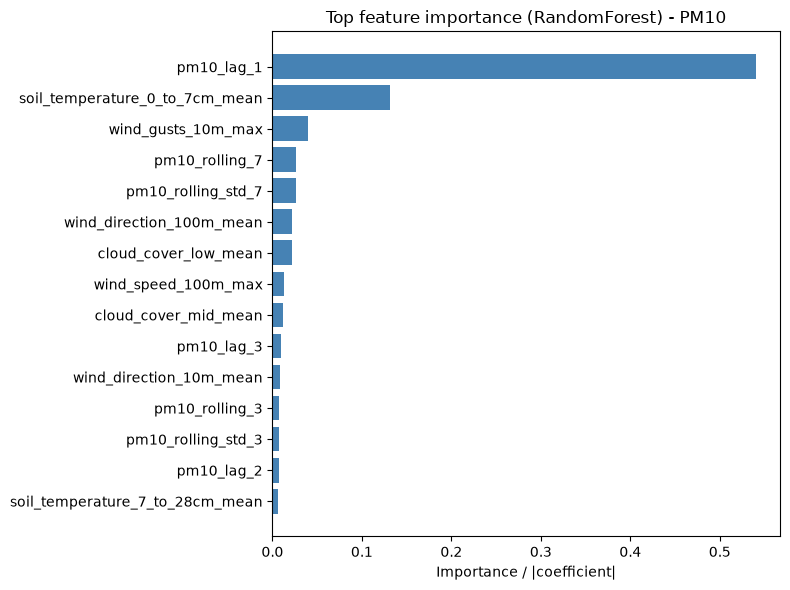

In [16]:
plt.figure(figsize=(8, 6))
plot_df = imp_df.head(15).iloc[::-1]
plt.barh(plot_df["feature"], plot_df["importance"], color="steelblue")
plt.xlabel("Importance / |coefficient|")
plt.title(f"Top feature importance ({best_model}) - {POLLUTANT.upper()}")
plt.tight_layout()
plt.show()

In [17]:
feature_names = list(X.columns)

FACTOR_GROUPS = {
    "Previous pollution (lag)": [f"{POLLUTANT}_lag_{d}" for d in LAGGED_DAYS],
    "Previous pollution (rolling)": [f"{POLLUTANT}_rolling_{w}" for w in ROLLING_WINDOWS] + [f"{POLLUTANT}_rolling_std_{w}" for w in ROLLING_WINDOWS],
    "Temperature": [c for c in feature_names if "temperature" in c or "dew_point" in c],
    "Humidity": [c for c in feature_names if "humidity" in c or "vapour_pressure" in c],
    "Wind": [c for c in feature_names if "wind" in c and "category" not in c] + [c for c in feature_names if c.startswith("wind_")],
    "Precipitation": [c for c in feature_names if "precip" in c or "rain" in c or "snowfall" in c or "snow_depth" in c],
    "Pressure": [c for c in feature_names if "pressure" in c],
    "Clouds & radiation": [c for c in feature_names if "cloud" in c or "radiation" in c or "sunshine" in c or "et0" in c],
    "Season / calendar": [c for c in feature_names if "month" in c or "dow" in c or "weekend" in c],
    "Soil": [c for c in feature_names if c.startswith("soil")],
    "Wind category": [c for c in feature_names if c.startswith("wind_weak") or c.startswith("wind_moderate") or c.startswith("wind_strong")],
    "Weather code": [c for c in feature_names if "weather_code" in c],
}

In [18]:
factor_importance = []
for factor, cols in FACTOR_GROUPS.items():
    present = [c for c in cols if c in feature_names]
    if not present:
        continue
    vals = [importance[list(feature_names).index(c)] for c in present]
    factor_importance.append({
        "factor": factor,
        "n_features": len(present),
        "importance_max": float(np.max(vals)),
        "importance_mean": float(np.mean(vals)),
    })

factor_df = pd.DataFrame(factor_importance).sort_values("importance_mean", ascending=False)
display(factor_df.round(4))

,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.5403,0.1858
9,Soil,8,0.1310,0.0199
2,Temperature,9,0.1310,0.0179
1,Previous pollution (rolling),4,0.0268,0.0170
4,Wind,20,0.0398,0.0097
7,Clouds & radiation,9,0.0217,0.0060
3,Humidity,4,0.0053,0.0047
6,Pressure,5,0.0053,0.0032
5,Precipitation,5,0.0039,0.0015
8,Season / calendar,5,0.0032,0.0014


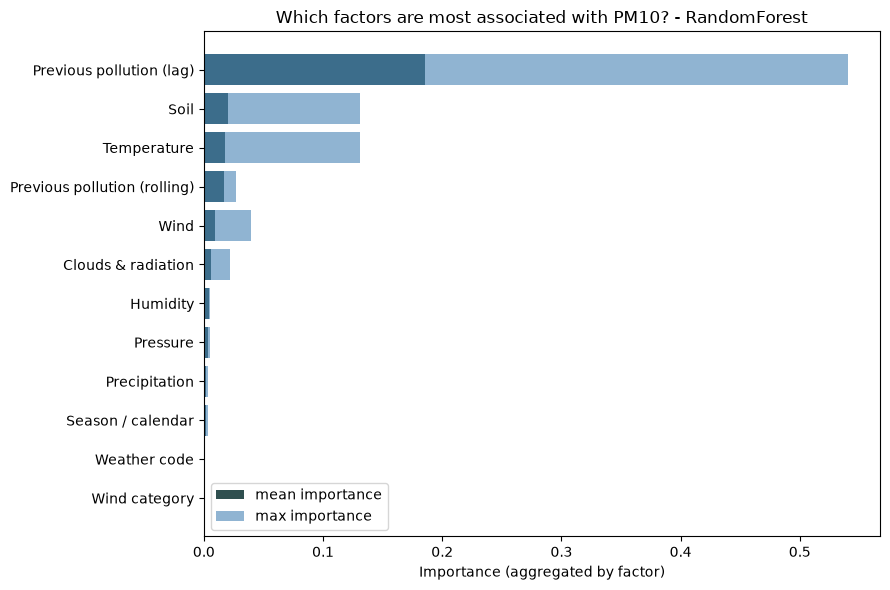

In [19]:
plt.figure(figsize=(9, 6))
plot_df = factor_df.iloc[::-1]
plt.barh(plot_df["factor"], plot_df["importance_mean"], color="darkslategray", label="mean importance")
plt.barh(plot_df["factor"], plot_df["importance_max"], color="steelblue", alpha=0.6, label="max importance")
plt.xlabel("Importance (aggregated by factor)")
plt.title(f"Which factors are most associated with {POLLUTANT.upper()}? - {best_model}")
plt.legend()
plt.tight_layout()
plt.show()


In [20]:
METRICS_OUT = PROCESSED_DIR / f"regression_metrics_{POLLUTANT}.parquet"
PRED_OUT = PROCESSED_DIR / f"regression_predictions_{POLLUTANT}.parquet"

In [21]:
results_df.to_parquet(METRICS_OUT)
comparison.to_parquet(PRED_OUT, index=False)
print(f"Saved: {METRICS_OUT.name}")
print(f"Saved: {PRED_OUT.name}")


Saved: regression_metrics_pm10.parquet
Saved: regression_predictions_pm10.parquet
